# M2: Scoring the v2 win model against its pre-registered criteria
v2 = `StandardScaler → LogisticRegression` on the pregame Elo gap (`elo_diff`), walk-forward 2019–2025. The criteria were fixed in `CLAUDE.md` **before** this notebook ran:

| # | Criterion | Pass if |
|---|---|---|
| S1 | Useful vs. knowing nothing | paired log loss vs. base rate: CI entirely below 0 |
| S2 | At least as good as raw Elo | paired log loss vs. raw Elo: CI upper bound < +0.005 |
| S3 | Honest probabilities | Brier reliability ≤ 0.002 **and** recalibration slope in [0.8, 1.2] |

If S2 or S3 fails, raw Elo becomes the deliverable.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score

from nfl_ats.data import HISTORY_SEASONS, PRIOR_SEASON, load_schedules
from nfl_ats.evaluate import (TEST_SEASONS, brier_decomposition, calibration_slope, paired_diff, reliability_table,
                              score)
from nfl_ats.win_model import TARGET, WIN_FEATURES, benchmark_predictions, build_win_table, win_walk_forward

sns.set_theme(style="whitegrid")
FIG_DIR = "../reports/figures"

## 1. Predictions
Each season 2019–2025 is predicted by a model fit only on earlier seasons. The benchmarks are lined up on the same games. Ties are excluded and counted.

In [2]:
table = build_win_table(load_schedules([PRIOR_SEASON] + HISTORY_SEASONS))
v2 = win_walk_forward(table, WIN_FEATURES, TEST_SEASONS)
bench = benchmark_predictions(table, TEST_SEASONS)
models = {"base rate": bench["base_rate"], "raw Elo": bench["elo"], "v2 (Elo + logistic)": v2, "market": bench["market"]}
y = v2[TARGET].to_numpy()
ties_in_test = int(table.loc[table["season"].isin(TEST_SEASONS), "is_tie"].sum())
print(f"{len(v2)} decided test games, {ties_in_test} ties excluded")

1865 decided test games, 6 ties excluded


## 2. Report card (pooled 2019–2025, 95% bootstrap CIs)

In [3]:
card = {}
for name, d in models.items():
    s = score(y, d["p"])
    card[name] = {"accuracy": s.loc["accuracy", "estimate"],
                  "acc 95% CI": f"[{s.loc['accuracy', 'ci_low']:.3f}, {s.loc['accuracy', 'ci_high']:.3f}]",
                  "log_loss": s.loc["log_loss", "estimate"], "brier": s.loc["brier", "estimate"],
                  "auc": roc_auc_score(y, d["p"]) if d["p"].nunique() > 7 else np.nan}
pd.DataFrame(card).T.round(4)

,accuracy,acc 95% CI,log_loss,brier,auc
base rate,0.531903,"[0.508, 0.554]",0.693256,0.25004,NaN
raw Elo,0.635925,"[0.614, 0.658]",0.638725,0.223528,0.691786
v2 (Elo + logistic),0.631635,"[0.610, 0.655]",0.639129,0.223659,0.690819
market,0.665416,"[0.643, 0.687]",0.608393,0.210547,0.727412


In [4]:
# Per season: log loss (lower is better)
pd.DataFrame({name: d.groupby("season").apply(lambda g: -np.mean(g[TARGET] * np.log(g["p"]) + (1 - g[TARGET]) * np.log(1 - g["p"])),
                                               include_groups=False) for name, d in models.items()}).round(4)

,base rate,raw Elo,v2 (Elo + logistic),market
season,,,,
2019,0.7011,0.6326,0.6382,0.6136
2020,0.7025,0.6237,0.6254,0.5901
2021,0.6952,0.6580,0.6564,0.6216
2022,0.6861,0.6404,0.6405,0.6085
2023,0.6871,0.6614,0.6600,0.6273
2024,0.6915,0.6148,0.6152,0.5875
2025,0.6903,0.6389,0.6373,0.6094


## 3. The verdict on S1–S3

In [5]:
s1 = paired_diff(y, bench["base_rate"]["p"], v2["p"]).loc["log_loss"]
s2 = paired_diff(y, bench["elo"]["p"], v2["p"]).loc["log_loss"]
decomp = brier_decomposition(y, v2["p"])
slope, slope_lo, slope_hi = calibration_slope(y, v2["p"])

verdict = pd.DataFrame({
    "S1 useful vs. base rate": {"measured": f"log loss diff {s1['diff']:+.4f} [{s1['ci_low']:+.4f}, {s1['ci_high']:+.4f}]",
                                "rule": "CI upper < 0", "PASS": s1["ci_high"] < 0},
    "S2 non-inferior to raw Elo": {"measured": f"log loss diff {s2['diff']:+.4f} [{s2['ci_low']:+.4f}, {s2['ci_high']:+.4f}]",
                                   "rule": "CI upper < +0.005", "PASS": s2["ci_high"] < 0.005},
    "S3a reliability": {"measured": f"{decomp['reliability']:.5f}", "rule": "<= 0.002", "PASS": decomp["reliability"] <= 0.002},
    "S3b calibration slope": {"measured": f"{slope:.3f} [{slope_lo:.3f}, {slope_hi:.3f}]", "rule": "0.8 to 1.2",
                              "PASS": 0.8 <= slope <= 1.2},
}).T
verdict

,measured,rule,PASS
S1 useful vs. base rate,"log loss diff -0.0541 [-0.0698, -0.0392]",CI upper < 0,True
S2 non-inferior to raw Elo,"log loss diff +0.0004 [-0.0011, +0.0019]",CI upper < +0.005,True
S3a reliability,0.00234,<= 0.002,False
S3b calibration slope,"0.947 [0.807, 1.106]",0.8 to 1.2,True


## 4. The honest gap to the market
The market is not a success criterion. The moneyline isn't verified as closing, and its source changes around 2023.

In [6]:
pd.concat({"v2 minus market": paired_diff(y, bench["market"]["p"], v2["p"]),
           "v2 minus raw Elo": paired_diff(y, bench["elo"]["p"], v2["p"])}).round(4)

diff  ci_low  ci_high
v2 minus market  accuracy -0.0338 -0.0520  -0.0150
                 log_loss  0.0307  0.0213   0.0401
                 brier     0.0131  0.0089   0.0173
v2 minus raw Elo accuracy -0.0043 -0.0102   0.0016
                 log_loss  0.0004 -0.0011   0.0019
                 brier     0.0001 -0.0005   0.0008

## 5. Reliability: when v2 says X%, does the home team win X% of the time?

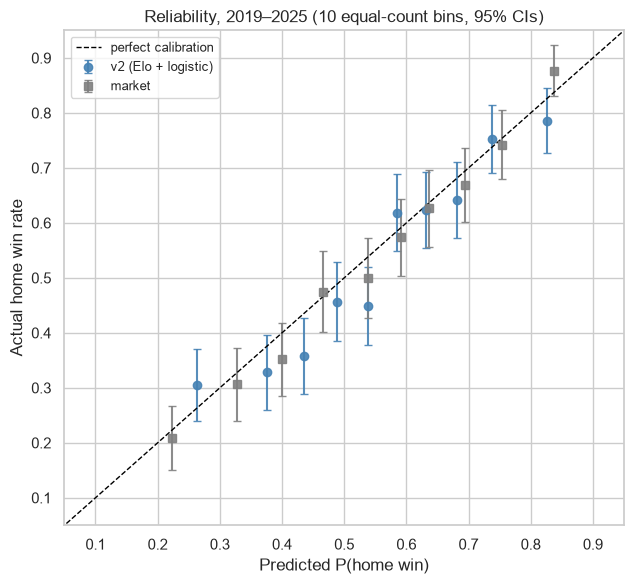

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for name, color, marker in [("v2 (Elo + logistic)", "steelblue", "o"), ("market", "gray", "s")]:
    r = reliability_table(y, models[name]["p"])
    se = np.sqrt(r["cover_rate"] * (1 - r["cover_rate"]) / r["games"])
    ax.errorbar(r["mean_p"], r["cover_rate"], yerr=1.96 * se, fmt=marker, ms=6, capsize=3, lw=1.5,
                color=color, label=name, alpha=0.9)
ax.plot([0, 1], [0, 1], color="black", ls="--", lw=1, label="perfect calibration")
ax.set(xlim=(0.05, 0.95), ylim=(0.05, 0.95), xlabel="Predicted P(home win)", ylabel="Actual home win rate",
       title="Reliability, 2019–2025 (10 equal-count bins, 95% CIs)")
ax.legend(fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/v2_win_reliability.png", dpi=150)

## 6. Post-hoc context (does NOT change the verdict)
How do raw Elo and the market do on S3? And how much reliability error would a *perfectly calibrated* model show by chance with these predictions and 1,865 games? The criteria above stand as written. This only explains them.

In [8]:
rows = {}
for name in ["v2 (Elo + logistic)", "raw Elo", "market"]:
    b, lo, hi = calibration_slope(y, models[name]["p"], n_boot=500)
    rows[name] = {"reliability": brier_decomposition(y, models[name]["p"])["reliability"],
                  "slope": b, "slope CI": f"[{lo:.3f}, {hi:.3f}]"}
rng = np.random.default_rng(0)
p_elo = models["raw Elo"]["p"].to_numpy()
sims = np.array([brier_decomposition((rng.uniform(size=len(p_elo)) < p_elo).astype(float), p_elo)["reliability"]
                 for _ in range(1000)])
print(f"Perfectly calibrated model, same predictions: reliability median {np.median(sims):.5f}, "
      f"95th pct {np.quantile(sims, 0.95):.5f}, P(> 0.002) = {np.mean(sims > 0.002):.2f}")
pd.DataFrame(rows).T.round(5)

Perfectly calibrated model, same predictions: reliability median 0.00112, 95th pct 0.00213, P(> 0.002) = 0.07


,reliability,slope,slope CI
v2 (Elo + logistic),0.002339,0.94745,"[0.793, 1.124]"
raw Elo,0.002075,0.924758,"[0.773, 1.096]"
market,0.00075,1.071902,"[0.945, 1.220]"


## Verdict (as pre-registered; wording corrected after the M2 skeptic review)
- **S1 PASS:** v2 beats the base rate, log loss −0.054 [−0.070, −0.039], in all 7 seasons. *(Near-certain before scoring: raw Elo's 0.639 was already known from D7, so S1 and S2 add little evidence.)*
- **S2 PASS:** v2 is non-inferior to raw Elo, +0.0004 [−0.0011, +0.0019]. They're effectively the same model.
- **S3 FAIL:** reliability 0.00234 > 0.002. The slope 0.947 is in range, but its CI [0.81, 1.11] nearly touches 0.8.
- **Rule outcome: raw Elo is the deliverable.** But **raw Elo fails S3a too** (0.00208). So **no model passes S3 on 2019–2025.** Raw Elo is the deliverable *by rule*, not because it's better calibrated. The v2-vs-Elo calibration order flips with the number of bins (difference CI [−0.0016, +0.0018]).

**Why S3 failed, two things both true:**
1. **A real home-team bias.** Both models over-predict home wins: +2.4 pts (v2) and +3.0 pts (Elo) pooled, vs. +1.4 for the market. It's concentrated in 2019–2021 (up to +6.7 pts), when home-field advantage shrank (2020 had no fans) and the models had learned it from 2016–2018. v2's reliability is at about the 96th percentile of what a perfectly calibrated model would show.
2. **A tight threshold.** A perfectly calibrated model with these predictions exceeds 0.002 about 7% of the time (mistake #10).

**Gap to the market:** v2 is 3.4 points behind in accuracy [1.5, 5.2] and +0.031 in log loss [+0.021, +0.040].